========== FIRST 5 ROWS ==========
         Date Country  Confirmed  Deaths  Recovered  Active  New_Cases  \
0  2025-01-01   India     1960.0    40.0     1590.0     330     1960.0   
1  2025-01-01     USA     2018.0    21.0     1396.0     601     2018.0   
2  2025-01-01  Brazil     1964.0    16.0     1790.0     158     1964.0   
3  2025-01-01      UK     1126.0    24.0      796.0     306     1126.0   
4  2025-01-01   Japan      659.0     8.0      521.0     130      659.0   

   New_Deaths  
0        40.0  
1        21.0  
2        16.0  
3        24.0  
4         8.0  

========== DATASET SHAPE ==========
(2190, 8)

========== COLUMN NAMES ==========
Index(['Date', 'Country', 'Confirmed', 'Deaths', 'Recovered', 'Active',
       'New_Cases', 'New_Deaths'],
      dtype='str')

========== DATA TYPES ==========
Date              str
Country           str
Confirmed     float64
Deaths        float64
Recovered     float64
Active          int64
New_Cases     float64
New_Deaths    float64
dtype

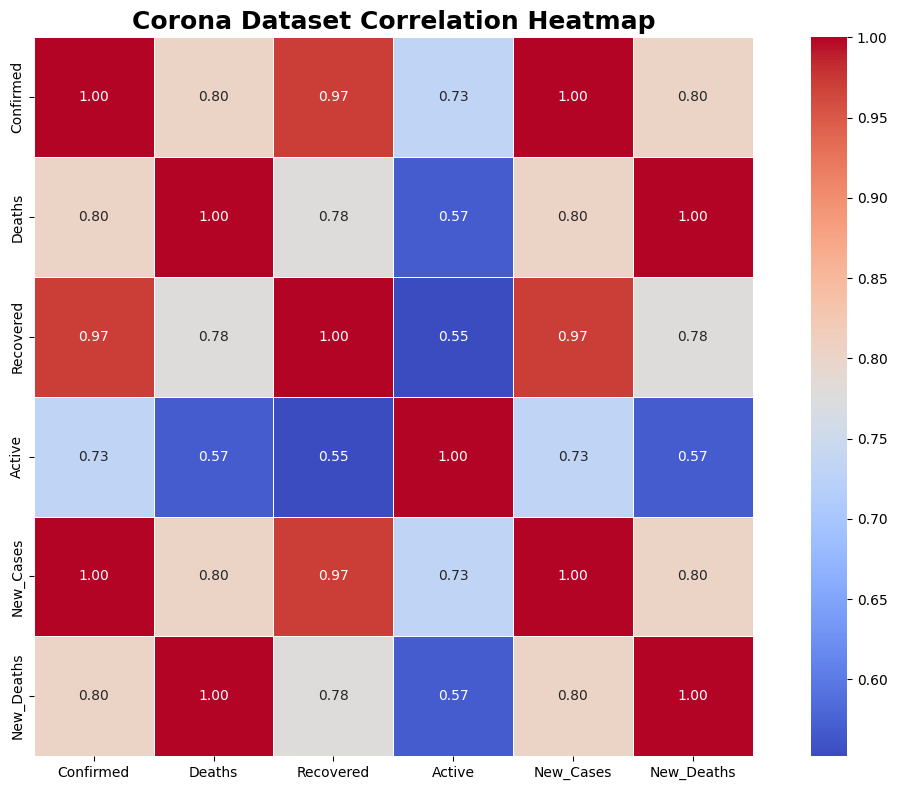

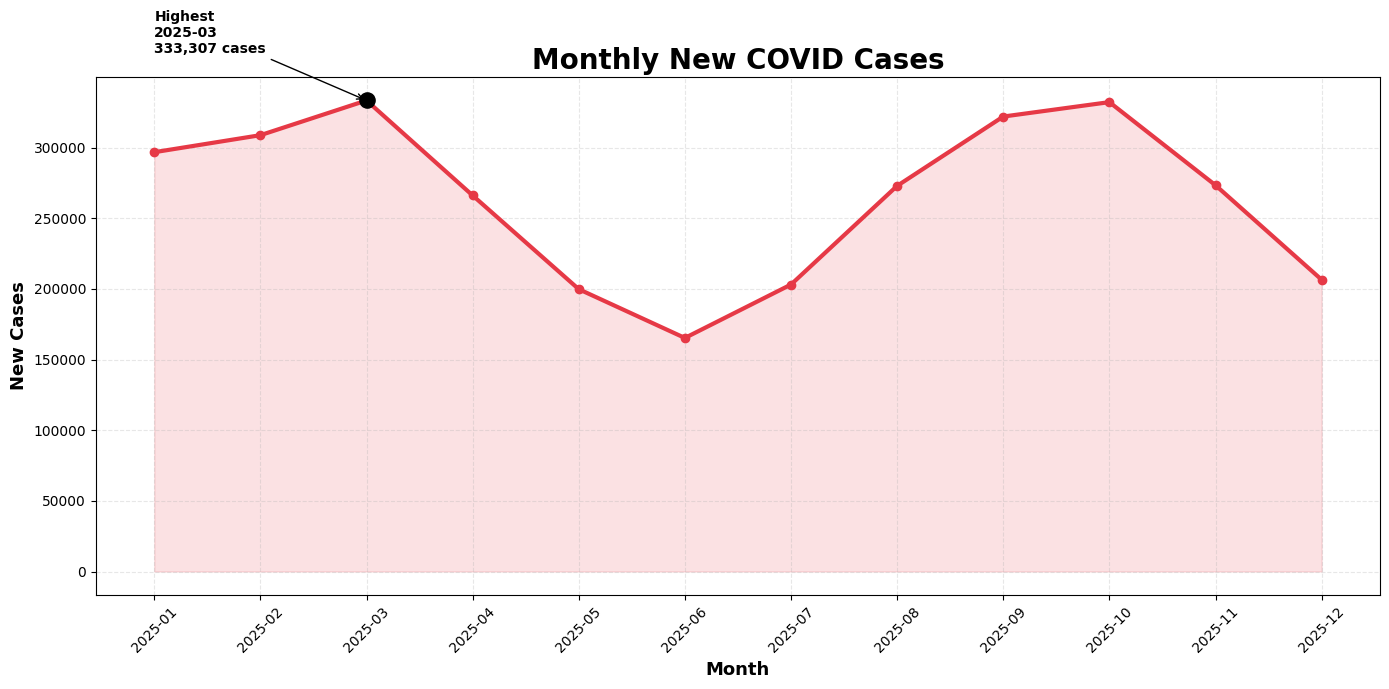

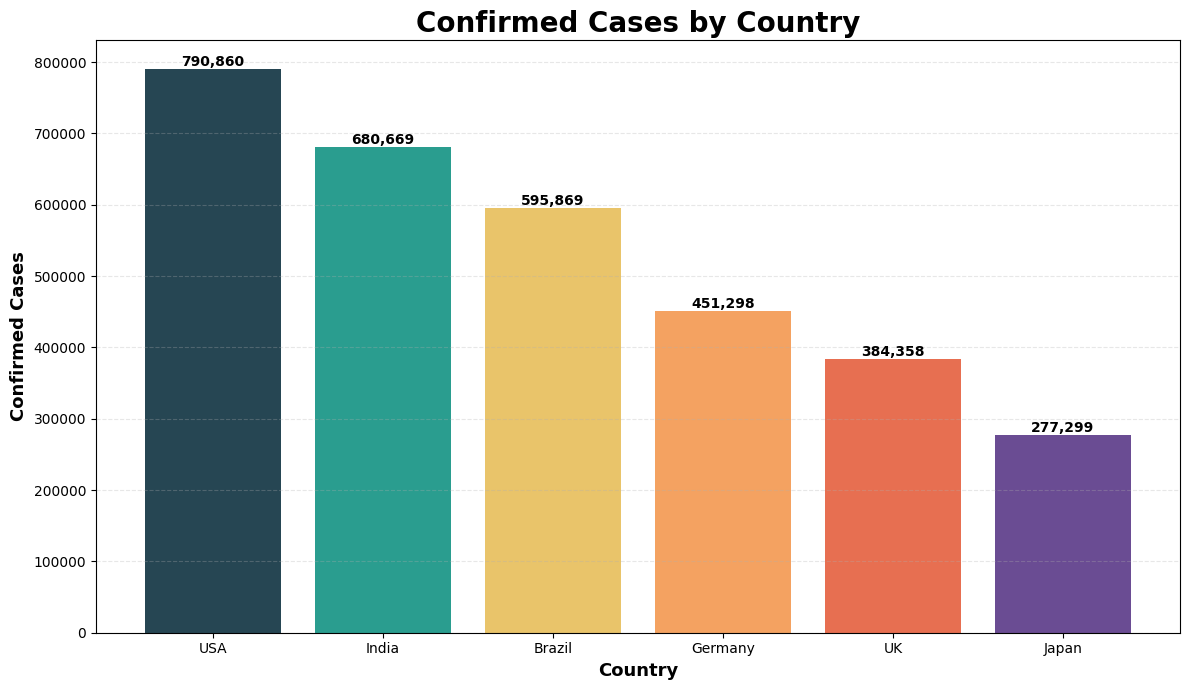

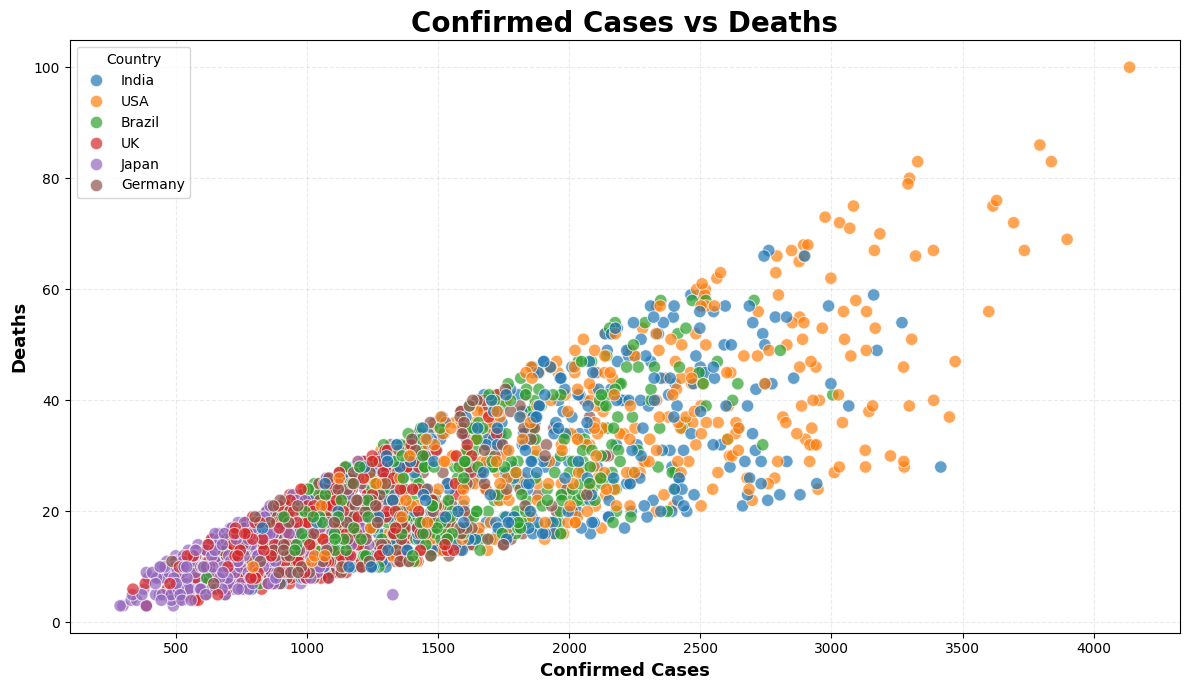

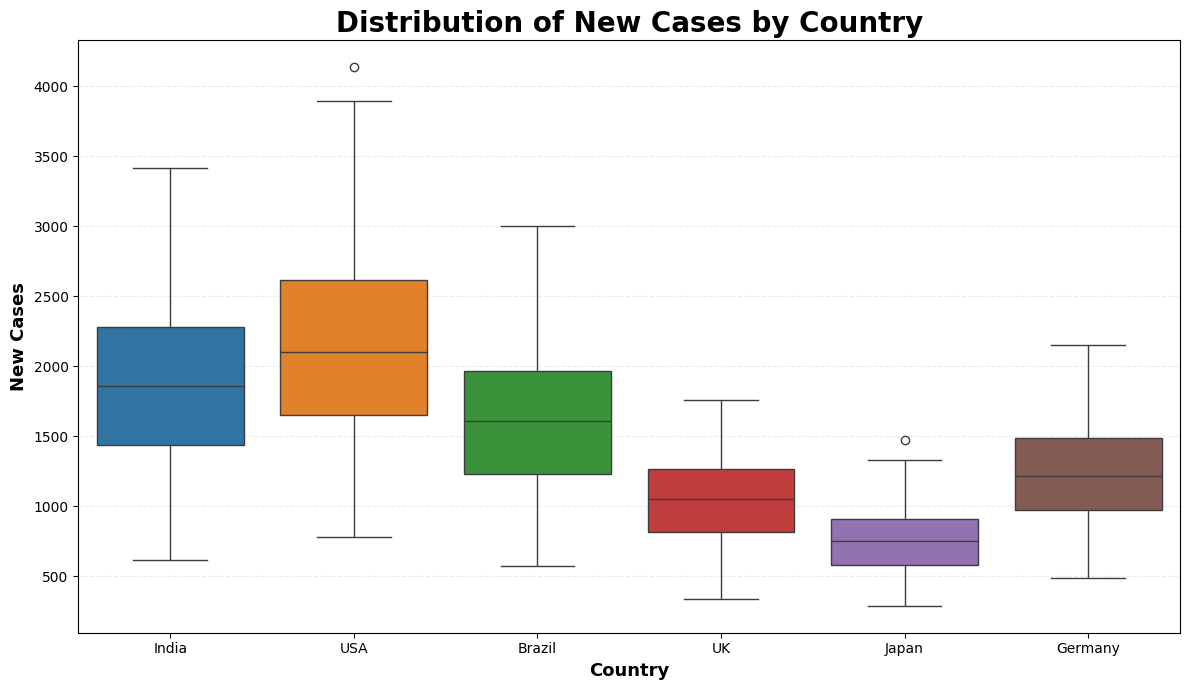


========== FINAL CONCLUSION ==========
USA had the highest confirmed cases in the dataset with 790,860 cases.
The month with the highest number of new cases was 2025-03 with 333,307 cases.
The month with the highest number of new deaths was 2025-03 with 5,404 deaths.
The correlation heatmap was used to identify relationships between confirmed cases, deaths, recovered cases, active cases, new cases and new deaths.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("corona_analysis_dataset.csv")

print("========== FIRST 5 ROWS ==========")
print(df.head())

print("\n========== DATASET SHAPE ==========")
print(df.shape)

print("\n========== COLUMN NAMES ==========")
print(df.columns)

print("\n========== DATA TYPES ==========")
print(df.dtypes)

print("\n========== DATASET INFORMATION ==========")
print(df.info())

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

print("\n========== DUPLICATES ==========")
print(df.duplicated().sum())

df["Date"] = pd.to_datetime(df["Date"])

numerical_columns = [
    "Confirmed",
    "Deaths",
    "Recovered",
    "Active",
    "New_Cases",
    "New_Deaths"
]

categorical_columns = [
    "Country"
]

for column in numerical_columns:
    df[column] = df[column].fillna(
        df[column].median()
    )

for column in categorical_columns:
    df[column] = df[column].fillna(
        df[column].mode()[0]
    )

df = df.drop_duplicates()

for column in numerical_columns:
    df[column] = df[column].astype(int)

print("\n========== AFTER CLEANING ==========")

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicates:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)


print("\n========== STATISTICAL ANALYSIS ==========")

for column in numerical_columns:

    print("\n", column)

    print("Mean:",
          round(df[column].mean(), 2))

    print("Median:",
          round(df[column].median(), 2))

    print("Variance:",
          round(df[column].var(), 2))

    print("Standard Deviation:",
          round(df[column].std(), 2))


print("\n========== MODE ==========")

print(
    "Most Frequent Country:",
    df["Country"].mode()[0]
)


df["Month"] = df["Date"].dt.to_period("M")


monthly_cases = (
    df.groupby("Month")["New_Cases"]
    .sum()
)

monthly_deaths = (
    df.groupby("Month")["New_Deaths"]
    .sum()
)


country_cases = (
    df.groupby("Country")["Confirmed"]
    .sum()
    .sort_values(ascending=False)
)


country_deaths = (
    df.groupby("Country")["Deaths"]
    .sum()
    .sort_values(ascending=False)
)


country_recovered = (
    df.groupby("Country")["Recovered"]
    .sum()
    .sort_values(ascending=False)
)


print("\n========== COUNTRY-WISE CASES ==========")
print(country_cases)

print("\n========== COUNTRY-WISE DEATHS ==========")
print(country_deaths)

print("\n========== COUNTRY-WISE RECOVERED ==========")
print(country_recovered)


highest_case_month = monthly_cases.idxmax()
highest_case_value = monthly_cases.max()

highest_death_month = monthly_deaths.idxmax()
highest_death_value = monthly_deaths.max()

highest_case_country = country_cases.idxmax()
highest_case_country_value = country_cases.max()

highest_death_country = country_deaths.idxmax()
highest_death_country_value = country_deaths.max()


print("\n========== MAJOR FINDINGS ==========")

print(
    "Highest Case Month:",
    highest_case_month
)

print(
    "Cases in Highest Month:",
    highest_case_value
)

print(
    "Highest Death Month:",
    highest_death_month
)

print(
    "Deaths in Highest Month:",
    highest_death_value
)

print(
    "Country with Highest Confirmed Cases:",
    highest_case_country
)

print(
    "Confirmed Cases:",
    highest_case_country_value
)

print(
    "Country with Highest Deaths:",
    highest_death_country
)

print(
    "Deaths:",
    highest_death_country_value
)


correlation = df[numerical_columns].corr()

print("\n========== CORRELATION MATRIX ==========")
print(correlation)


plt.figure(
    figsize=(12, 8)
)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    square=True
)

plt.title(
    "Corona Dataset Correlation Heatmap",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.show()


plt.figure(
    figsize=(14, 7)
)

plt.plot(
    monthly_cases.index.astype(str),
    monthly_cases.values,
    marker="o",
    linewidth=3,
    color="#E63946"
)

plt.fill_between(
    range(len(monthly_cases)),
    monthly_cases.values,
    alpha=0.15,
    color="#E63946"
)

plt.title(
    "Monthly New COVID Cases",
    fontsize=20,
    fontweight="bold"
)

plt.xlabel(
    "Month",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel(
    "New Cases",
    fontsize=13,
    fontweight="bold"
)

plt.xticks(
    rotation=45
)

plt.grid(
    linestyle="--",
    alpha=0.3
)

highest_index = list(
    monthly_cases.index
).index(
    highest_case_month
)

plt.scatter(
    highest_index,
    highest_case_value,
    color="black",
    s=120,
    zorder=5
)

plt.annotate(
    f"Highest\n{highest_case_month}\n{highest_case_value:,} cases",
    xy=(
        highest_index,
        highest_case_value
    ),
    xytext=(
        highest_index - 2,
        highest_case_value * 1.1
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="black"
    ),
    fontsize=10,
    fontweight="bold"
)

plt.tight_layout()

plt.show()


plt.figure(
    figsize=(12, 7)
)

colors = [
    "#264653",
    "#2A9D8F",
    "#E9C46A",
    "#F4A261",
    "#E76F51",
    "#6A4C93"
]

bars = plt.bar(
    country_cases.index,
    country_cases.values,
    color=colors[:len(country_cases)]
)

plt.title(
    "Confirmed Cases by Country",
    fontsize=20,
    fontweight="bold"
)

plt.xlabel(
    "Country",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel(
    "Confirmed Cases",
    fontsize=13,
    fontweight="bold"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()

plt.show()


plt.figure(
    figsize=(12, 7)
)

sns.scatterplot(
    data=df,
    x="Confirmed",
    y="Deaths",
    hue="Country",
    s=80,
    alpha=0.7
)

plt.title(
    "Confirmed Cases vs Deaths",
    fontsize=20,
    fontweight="bold"
)

plt.xlabel(
    "Confirmed Cases",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel(
    "Deaths",
    fontsize=13,
    fontweight="bold"
)

plt.grid(
    linestyle="--",
    alpha=0.25
)

plt.legend(
    title="Country"
)

plt.tight_layout()

plt.show()


plt.figure(
    figsize=(12, 7)
)

sns.boxplot(
    data=df,
    x="Country",
    y="New_Cases",
    hue="Country",
    legend=False
)

plt.title(
    "Distribution of New Cases by Country",
    fontsize=20,
    fontweight="bold"
)

plt.xlabel(
    "Country",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel(
    "New Cases",
    fontsize=13,
    fontweight="bold"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()

plt.show()


print("\n========== FINAL CONCLUSION ==========")

print(
    f"{highest_case_country} had the highest "
    f"confirmed cases in the dataset with "
    f"{highest_case_country_value:,} cases."
)

print(
    f"The month with the highest number of "
    f"new cases was {highest_case_month} "
    f"with {highest_case_value:,} cases."
)

print(
    f"The month with the highest number of "
    f"new deaths was {highest_death_month} "
    f"with {highest_death_value:,} deaths."
)

print(
    "The correlation heatmap was used to "
    "identify relationships between confirmed "
    "cases, deaths, recovered cases, active cases, "
    "new cases and new deaths."
)

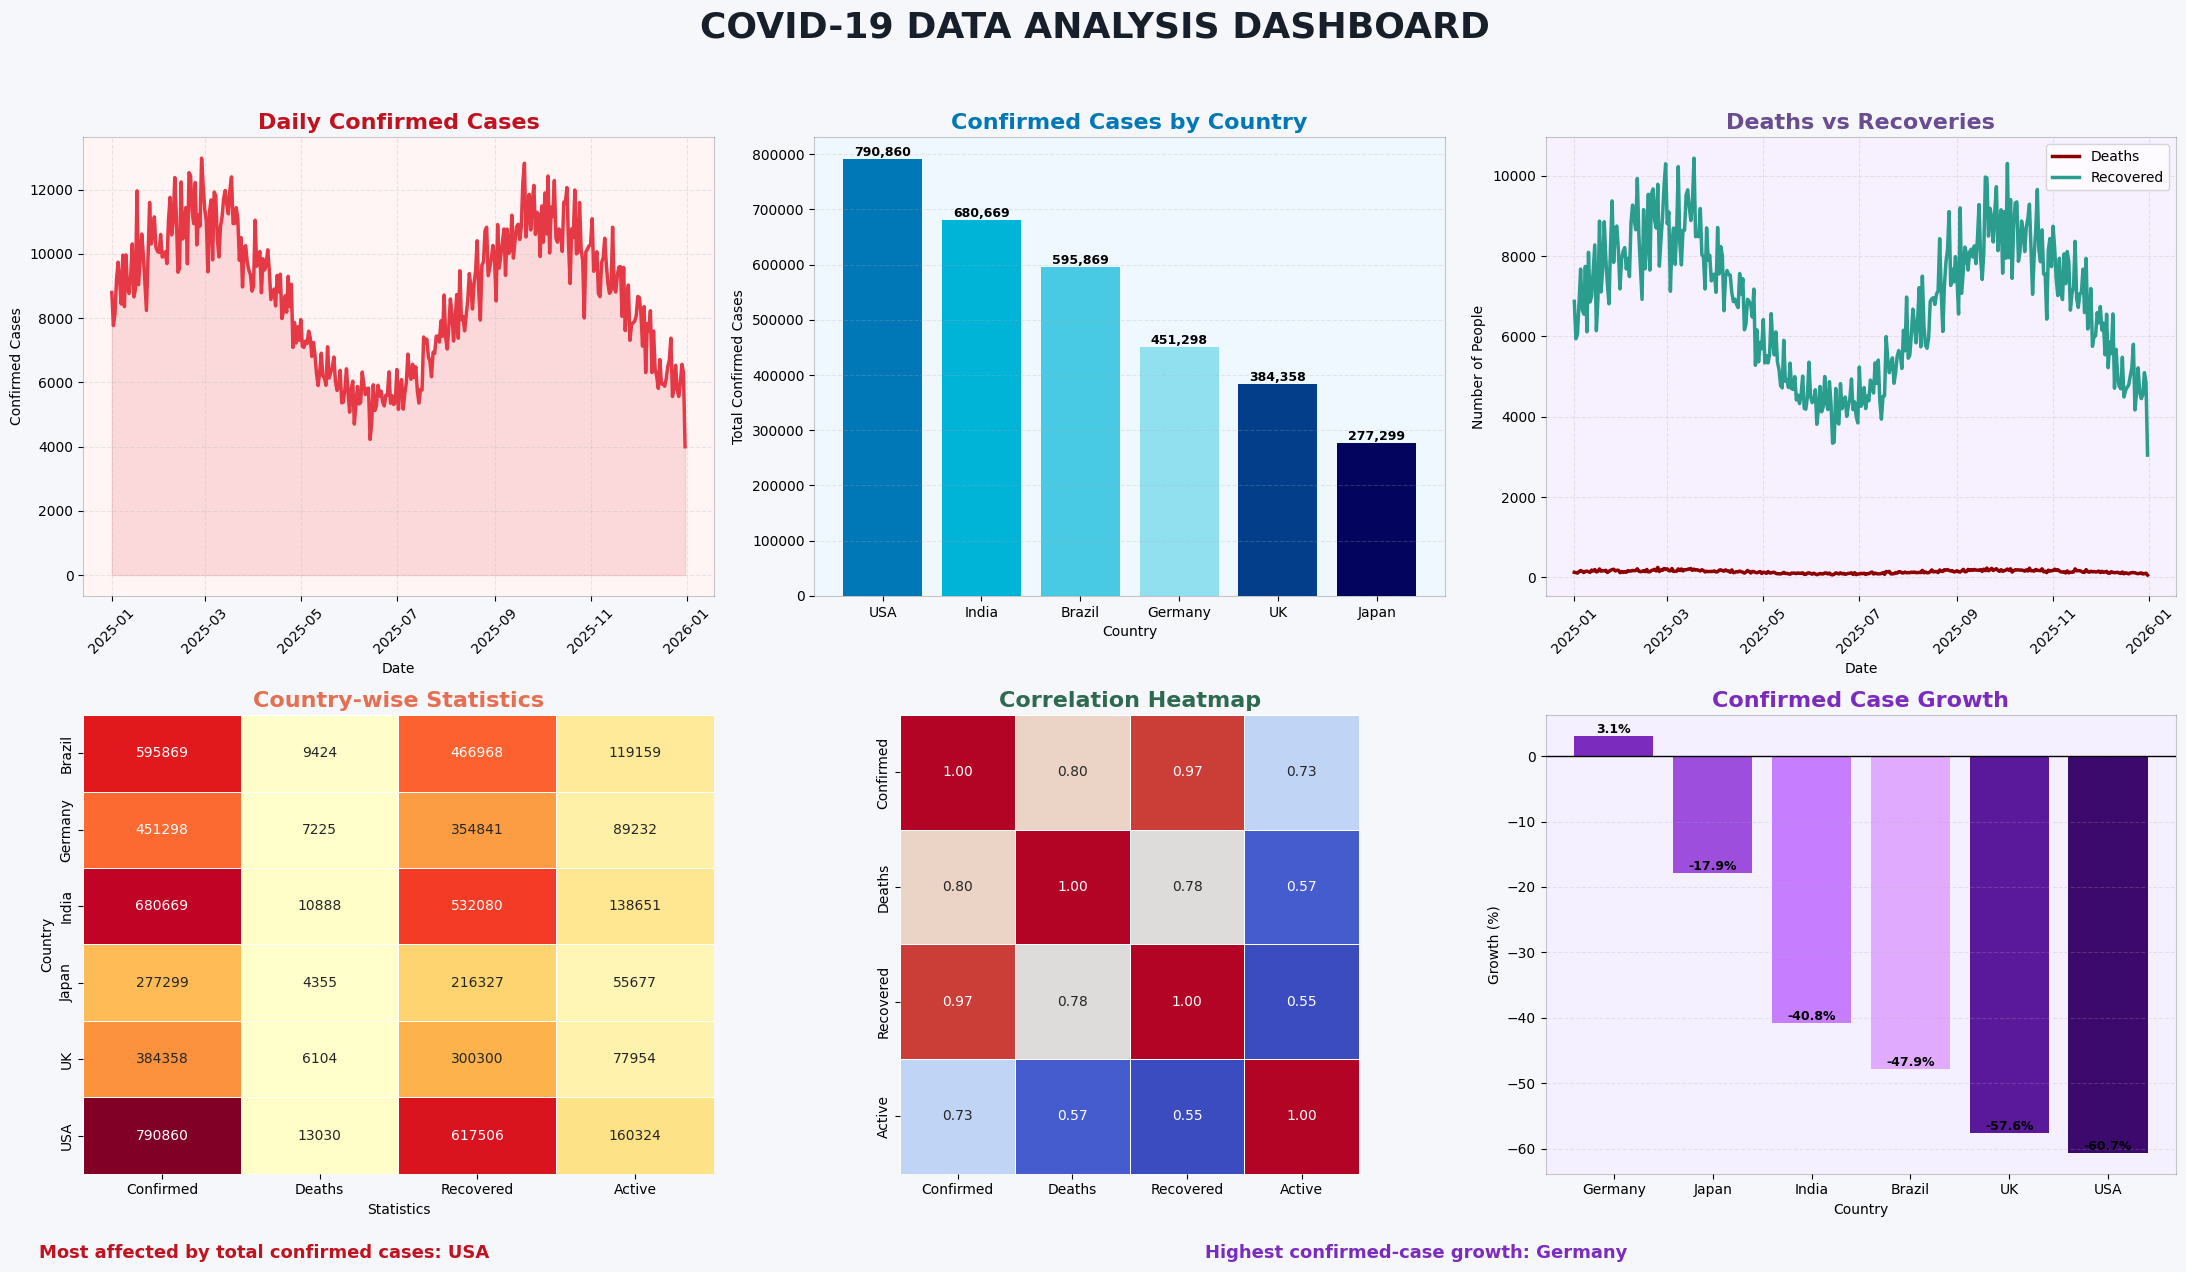

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("corona_analysis_dataset.csv")

df["Date"] = pd.to_datetime(df["Date"])

numeric_columns = [
    "Confirmed",
    "Deaths",
    "Recovered",
    "Active"
]

for column in numeric_columns:
    df[column] = df[column].fillna(
        df[column].median()
    )

df["Country"] = df["Country"].fillna(
    df["Country"].mode()[0]
)

df = df.drop_duplicates()

for column in numeric_columns:
    df[column] = df[column].astype(int)

df["Month"] = df["Date"].dt.to_period("M")

daily_confirmed = (
    df.groupby("Date")["Confirmed"]
    .sum()
)

daily_deaths = (
    df.groupby("Date")["Deaths"]
    .sum()
)

daily_recovered = (
    df.groupby("Date")["Recovered"]
    .sum()
)

country_statistics = (
    df.groupby("Country")[numeric_columns]
    .sum()
)

country_confirmed = (
    df.groupby("Country")["Confirmed"]
    .sum()
    .sort_values(ascending=False)
)

country_deaths = (
    df.groupby("Country")["Deaths"]
    .sum()
    .sort_values(ascending=False)
)

country_recovered = (
    df.groupby("Country")["Recovered"]
    .sum()
    .sort_values(ascending=False)
)

country_active = (
    df.groupby("Country")["Active"]
    .sum()
    .sort_values(ascending=False)
)

correlation = df[numeric_columns].corr()

country_growth = {}

for country in df["Country"].unique():

    country_data = (
        df[df["Country"] == country]
        .sort_values("Date")
    )

    first_value = country_data["Confirmed"].iloc[0]
    last_value = country_data["Confirmed"].iloc[-1]

    if first_value != 0:
        growth = (
            (last_value - first_value)
            / first_value
        ) * 100
    else:
        growth = 0

    country_growth[country] = growth

growth_df = (
    pd.Series(country_growth)
    .sort_values(ascending=False)
)


most_affected_country = country_confirmed.idxmax()
highest_growth_country = growth_df.idxmax()


fig, axes = plt.subplots(
    2,
    3,
    figsize=(22, 13)
)

fig.patch.set_facecolor("#F5F7FA")

fig.suptitle(
    "COVID-19 DATA ANALYSIS DASHBOARD",
    fontsize=26,
    fontweight="bold",
    color="#17202A",
    y=0.98
)


axes[0, 0].set_facecolor("#FFF5F5")

axes[0, 0].plot(
    daily_confirmed.index,
    daily_confirmed.values,
    color="#E63946",
    linewidth=2.5
)

axes[0, 0].fill_between(
    daily_confirmed.index,
    daily_confirmed.values,
    color="#E63946",
    alpha=0.15
)

axes[0, 0].set_title(
    "Daily Confirmed Cases",
    fontsize=16,
    fontweight="bold",
    color="#C1121F"
)

axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("Confirmed Cases")

axes[0, 0].grid(
    linestyle="--",
    alpha=0.25
)

axes[0, 0].tick_params(
    axis="x",
    rotation=45
)


axes[0, 1].set_facecolor("#F0F8FF")

bars = axes[0, 1].bar(
    country_confirmed.index,
    country_confirmed.values,
    color=[
        "#0077B6",
        "#00B4D8",
        "#48CAE4",
        "#90E0EF",
        "#023E8A",
        "#03045E"
    ]
)

axes[0, 1].set_title(
    "Confirmed Cases by Country",
    fontsize=16,
    fontweight="bold",
    color="#0077B6"
)

axes[0, 1].set_xlabel("Country")
axes[0, 1].set_ylabel("Total Confirmed Cases")

axes[0, 1].grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

for bar in bars:

    height = bar.get_height()

    axes[0, 1].text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )


axes[0, 2].set_facecolor("#F6F0FF")

axes[0, 2].plot(
    daily_deaths.index,
    daily_deaths.values,
    color="#8E0000",
    linewidth=2.5,
    label="Deaths"
)

axes[0, 2].plot(
    daily_recovered.index,
    daily_recovered.values,
    color="#2A9D8F",
    linewidth=2.5,
    label="Recovered"
)

axes[0, 2].set_title(
    "Deaths vs Recoveries",
    fontsize=16,
    fontweight="bold",
    color="#6A4C93"
)

axes[0, 2].set_xlabel("Date")
axes[0, 2].set_ylabel("Number of People")

axes[0, 2].legend()

axes[0, 2].grid(
    linestyle="--",
    alpha=0.25
)

axes[0, 2].tick_params(
    axis="x",
    rotation=45
)


axes[1, 0].set_facecolor("#FFF9E6")

sns.heatmap(
    country_statistics,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=axes[1, 0],
    cbar=False
)

axes[1, 0].set_title(
    "Country-wise Statistics",
    fontsize=16,
    fontweight="bold",
    color="#E76F51"
)

axes[1, 0].set_xlabel("Statistics")
axes[1, 0].set_ylabel("Country")


axes[1, 1].set_facecolor("#F0FFF4")

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    square=True,
    ax=axes[1, 1],
    cbar=False
)

axes[1, 1].set_title(
    "Correlation Heatmap",
    fontsize=16,
    fontweight="bold",
    color="#2D6A4F"
)


axes[1, 2].set_facecolor("#F5F0FF")

bars = axes[1, 2].bar(
    growth_df.index,
    growth_df.values,
    color=[
        "#7B2CBF",
        "#9D4EDD",
        "#C77DFF",
        "#E0AAFF",
        "#5A189A",
        "#3C096C"
    ]
)

axes[1, 2].set_title(
    "Confirmed Case Growth",
    fontsize=16,
    fontweight="bold",
    color="#7B2CBF"
)

axes[1, 2].set_xlabel("Country")
axes[1, 2].set_ylabel("Growth (%)")

axes[1, 2].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1, 2].grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

for bar in bars:

    height = bar.get_height()

    axes[1, 2].text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )


for ax in axes.flat:

    for spine in ax.spines.values():
        spine.set_alpha(0.2)


fig.text(
    0.02,
    0.02,
    f"Most affected by total confirmed cases: {most_affected_country}",
    fontsize=13,
    fontweight="bold",
    color="#C1121F"
)

fig.text(
    0.55,
    0.02,
    f"Highest confirmed-case growth: {highest_growth_country}",
    fontsize=13,
    fontweight="bold",
    color="#7B2CBF"
)

plt.tight_layout(
    rect=[0, 0.04, 1, 0.95]
)

plt.show()